<a href="https://colab.research.google.com/github/reetikaChauhan/Road-Crack-Detection/blob/main/crack_detection_pipeline.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Road Crack Detection: An End-to-End Pipeline

Dash-camera road images go in; **crack locations, severity, and type** come out.

```
 dash-cam image
      |
      v
 [1] SAM point prompt  --> road mask
 [2] Sobel edges       --> high-frequency (texture/crack) map
      |   overlap + 200x200 grid  (>=80% road, edges present)
      v
 candidate crops
      |
      v
 [3] Fine-tuned ViT binary classifier  (keep P(crack) >= 0.195  -> high-recall filter)
      |
      v
 ViT survivors
      |
      v
 [4] Qwen crack verification (yes/no)  --> drops shadows, curb edges, stains, joints, etc.
      |
      v
 verified crack crops
      |
      v
 [5] Qwen vision-language model --> severity (Extreme..Negligible) + type (Longitudinal / Transverse / Alligator / Other)
      |
      v
 results table: image name | crop position (x, y) | severity | type   + annotated images
```

**Why this design?** Running a large vision-language model on every region of every image is far too slow.
Each stage is a cheap filter that shrinks the workload for the next, more expensive one.

### Folder layout

```
MyDrive/crack_pipeline/
├── input_images/          <- dash-cam .png/.jpg images here (already cropped to remove the car hood)
├── models/
│   ├── final_model.pt     <- trained ViT weights
│   └── qwen_..._4bit/     <- created automatically on first run (4-bit Qwen cached here, ~5-6 GB)
└── outputs/               <- created automatically; results are written here
```

## 0. Setup

In [ ]:
!pip install -q ultralytics transformers accelerate bitsandbytes

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 2.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 38.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.1/43.1 MB 74.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.5/96.5 kB 11.8 MB/s eta 0:00:00


In [ ]:
import os, re, json, shutil, gc
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from tqdm.auto import tqdm

import torch
from torch import nn
from transformers import (
    ViTForImageClassification, ViTImageProcessor,
    AutoProcessor, AutoModelForImageTextToText, BitsAndBytesConfig,
)
from ultralytics import SAM

try:
    from google.colab import drive
    drive.mount("/content/drive")
except ImportError:
    print("Not running in Colab - using local paths.")

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device, torch.cuda.get_device_name(0) if torch.cuda.is_available() else "")

Mounted at /content/drive
Device: cuda NVIDIA RTX PRO 6000 Blackwell Server Edition


### Configuration
Everything you might want to tweak lives in this one cell.

In [ ]:
# ---------- Paths ----------
DRIVE_ROOT   = "/content/drive/MyDrive/crack_pipeline"
INPUT_DIR    = f"{DRIVE_ROOT}/input_images"
VIT_WEIGHTS  = f"{DRIVE_ROOT}/models/final_model.pt"
OUTPUT_DIR   = f"{DRIVE_ROOT}/outputs"

# ---------- Stage 1: SAM + Sobel prefilter ----------
SAM_WEIGHTS          = "sam_b.pt"   # auto-downloaded by ultralytics
GRID_SIZE            = 200          # crop size in pixels
SOBEL_BINARY_THRESH  = 30           # threshold for the full-image HFC map
PATCH_HFC_THRESH     = 20           # mean-gradient threshold inside a crop
MIN_ROAD_COVERAGE    = 0.8          # fraction of crop that must be road
FULL_CROPS_ONLY      = True         # skip partial crops at the image border

# ---------- Stage 2: ViT binary classifier ----------
VIT_BACKBONE   = "google/vit-base-patch16-224"
VIT_THRESHOLD  = 0.4              # keep crops with P(crack) >= this (high-recall)
VIT_DROP_PROB  = 0.5                # must match training
VIT_BATCH_SIZE = 32

# ---------- Stage 3: Qwen severity + type ----------
# The original scripts used "Qwen/Qwen3.5-397B-A17B", which needs a multi-GPU server.
# On Colab we use a smaller Qwen VL model (Qwen2.5-VL-7B with 4-bit quantization). Set a string to override.
QWEN_MODEL_ID      = None
QWEN_4BIT          = True           # 4-bit NF4 quantization (7B model ~5-6 GB of VRAM, fits a free T4)
QWEN_DRIVE_ROOT    = f"{DRIVE_ROOT}/models"   # Qwen is cached in a subfolder of this directory
QWEN_MAX_NEW_TOK   = 8
QWEN_CROP_UPSCALE  = 448            # upscale 200x200 crops before sending to Qwen (helps small cracks)
QWEN_VERIFY_CRACKS = True           # Stage 3b: Qwen yes/no check that removes ViT false positives
QWEN_KEEP_UNKNOWN  = False          # if Qwen's yes/no answer can't be parsed: True = keep crop, False = drop it

# ---------- Run control ----------
MAX_IMAGES = None                   # e.g. 5 for a quick live demo; None = all images

os.makedirs(OUTPUT_DIR, exist_ok=True)
for sub in ["annotated", "crops", "rejected_by_qwen"]:
    os.makedirs(f"{OUTPUT_DIR}/{sub}", exist_ok=True)

## 1. Prefilter: SAM road mask + Sobel high-frequency map
SAM is prompted with a single foreground point on the road. Sobel gradients highlight crack-like texture.
Only grid cells that are mostly road **and** contain edge energy become candidates.

In [ ]:
sam_model = SAM(SAM_WEIGHTS)

def segment_road(image_bgr):
    """SAM point-prompt road mask -> uint8 (0/255), same size as the image. None if SAM finds nothing."""
    h, w = image_bgr.shape[:2]
    point = [[w // 3, int(h * 0.79)]]           # lower-left-of-center, typical road location
    res = sam_model.predict(image_bgr, points=point, labels=[1], conf=0.35, iou=0.7, verbose=False)
    if res[0].masks is None:
        return None
    mask = res[0].masks.data[0].cpu().numpy()
    if mask.shape != (h, w):
        mask = cv2.resize(mask, (w, h), interpolation=cv2.INTER_NEAREST)
    return (mask > 0).astype(np.uint8) * 255

def extract_hfc(image_bgr, threshold=SOBEL_BINARY_THRESH):
    """Binary high-frequency-component map from Sobel gradient magnitude."""
    gray = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2GRAY)
    sx = cv2.Sobel(gray, cv2.CV_64F, 1, 0, ksize=3)
    sy = cv2.Sobel(gray, cv2.CV_64F, 0, 1, ksize=3)
    mag = np.sqrt(sx**2 + sy**2)
    mag = cv2.normalize(mag, None, 0, 255, cv2.NORM_MINMAX)
    _, binary = cv2.threshold(mag, threshold, 255, cv2.THRESH_BINARY)
    return binary.astype(np.uint8)

def patch_has_hfc(patch_bgr, threshold=PATCH_HFC_THRESH):
    gray = cv2.cvtColor(patch_bgr, cv2.COLOR_BGR2GRAY)
    sx = cv2.Sobel(gray, cv2.CV_64F, 1, 0, ksize=3)
    sy = cv2.Sobel(gray, cv2.CV_64F, 0, 1, ksize=3)
    return np.mean(np.sqrt(sx**2 + sy**2)) > threshold

def find_candidate_crops(image_bgr, road_mask, hfc_map):
    """Slide a GRID_SIZE grid over the image; return (list of candidate boxes, total grid cells)."""
    H, W = image_bgr.shape[:2]
    overlap = cv2.bitwise_and(hfc_map, road_mask)
    boxes, total = [], 0
    for y in range(0, H, GRID_SIZE):
        for x in range(0, W, GRID_SIZE):
            x2, y2 = min(x + GRID_SIZE, W), min(y + GRID_SIZE, H)
            if FULL_CROPS_ONLY and (x2 - x < GRID_SIZE or y2 - y < GRID_SIZE):
                continue
            total += 1
            road_ok    = np.mean(road_mask[y:y2, x:x2] > 0) > MIN_ROAD_COVERAGE
            overlap_ok = np.count_nonzero(overlap[y:y2, x:x2]) > 0
            if road_ok and overlap_ok and patch_has_hfc(image_bgr[y:y2, x:x2]):
                boxes.append({"x": x, "y": y, "x_end": x2, "y_end": y2})
    return boxes, total

## 2. Trained ViT binary classifier (no retraining)
We rebuild the exact training architecture (ViT backbone + `Dropout -> Linear(1)` head), load `final_model.pt`,
and score every candidate crop. The **0.195 threshold** is deliberately low so that essentially every real crack is retained;
false positives are handled by the next stage.

In [ ]:
def create_vit():
    m = ViTForImageClassification.from_pretrained(VIT_BACKBONE, num_labels=1, ignore_mismatched_sizes=True)
    m.config.hidden_dropout_prob = VIT_DROP_PROB
    m.config.attention_probs_dropout_prob = VIT_DROP_PROB
    m.classifier = nn.Sequential(nn.Dropout(VIT_DROP_PROB), nn.Linear(m.config.hidden_size, 1))
    return m

assert os.path.isfile(VIT_WEIGHTS), f"ViT weights not found at {VIT_WEIGHTS}"
vit_processor = ViTImageProcessor.from_pretrained(VIT_BACKBONE)
vit_model = create_vit()
state = torch.load(VIT_WEIGHTS, map_location=device)
if isinstance(state, dict) and "model_state_dict" in state:
    state = state["model_state_dict"]
missing, unexpected = vit_model.load_state_dict(state, strict=False)
print("Missing keys:", missing, "| Unexpected keys:", unexpected)   # both should be empty
vit_model.to(device).eval()

def bgr_to_pil(bgr):
    return Image.fromarray(cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB))

@torch.no_grad()
def vit_crack_probabilities(crops_bgr):
    """P(crack) for a list of BGR crops."""
    probs = []
    for i in range(0, len(crops_bgr), VIT_BATCH_SIZE):
        batch = [bgr_to_pil(c) for c in crops_bgr[i:i + VIT_BATCH_SIZE]]
        pix = vit_processor(images=batch, return_tensors="pt")["pixel_values"].to(device)
        logits = vit_model(pixel_values=pix).logits.squeeze(-1)
        probs.extend(torch.sigmoid(logits).reshape(-1).cpu().tolist())
    return probs

preprocessor_config.json:   0%|          | 0.00/160 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/69.7k [00:00<?, ?B/s]

[transformers] You passed `num_labels=1` which is incompatible to the `id2label` map of length `1000`.


model.safetensors: reconstructing file:   0%|          |  0.00B /  346MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

[transformers] ViTForImageClassification LOAD REPORT from: google/vit-base-patch16-224
Key               | Status   |                                                                                          
------------------+----------+------------------------------------------------------------------------------------------
classifier.weight | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([1000, 768]) vs model:torch.Size([1, 768])
classifier.bias   | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([1000]) vs model:torch.Size([1])          

Notes:
- MISMATCH:	ckpt weights were loaded, but they did not match the original empty weight shapes.


Missing keys: ['vit.layers.0.attention.q_proj.weight', 'vit.layers.0.attention.q_proj.bias', 'vit.layers.0.attention.k_proj.weight', 'vit.layers.0.attention.k_proj.bias', 'vit.layers.0.attention.v_proj.weight', 'vit.layers.0.attention.v_proj.bias', 'vit.layers.0.attention.o_proj.weight', 'vit.layers.0.attention.o_proj.bias', 'vit.layers.0.layernorm_before.weight', 'vit.layers.0.layernorm_before.bias', 'vit.layers.0.layernorm_after.weight', 'vit.layers.0.layernorm_after.bias', 'vit.layers.0.mlp.fc1.weight', 'vit.layers.0.mlp.fc1.bias', 'vit.layers.0.mlp.fc2.weight', 'vit.layers.0.mlp.fc2.bias', 'vit.layers.1.attention.q_proj.weight', 'vit.layers.1.attention.q_proj.bias', 'vit.layers.1.attention.k_proj.weight', 'vit.layers.1.attention.k_proj.bias', 'vit.layers.1.attention.v_proj.weight', 'vit.layers.1.attention.v_proj.bias', 'vit.layers.1.attention.o_proj.weight', 'vit.layers.1.attention.o_proj.bias', 'vit.layers.1.layernorm_before.weight', 'vit.layers.1.layernorm_before.bias', 'vit.laye

## 3. Qwen vision-language model: verification, severity, and type
Qwen is quantized to 4-bit (NF4) and cached on Google Drive. **First run:** it is downloaded from Hugging Face, quantized, and saved to Drive. **Every later session:** it is read directly from Drive, which is faster and needs no Hugging Face download. It is only loaded into GPU memory the first time a Qwen call is made (`get_qwen()`).
The VLM is used twice on ViT survivors:
1. **Verification (yes/no):** a strict prompt that rejects shadows, stains, curb/sidewalk boundaries, and normal joints, removing the ViT's false positives.
2. **Description:** only verified crops get a severity and a crack type (two constrained prompts).

In [ ]:
'''
def pick_qwen_id():
    if QWEN_MODEL_ID:
        return QWEN_MODEL_ID
    if QWEN_4BIT:
        return "Qwen/Qwen2.5-VL-7B-Instruct"
    if torch.cuda.is_available() and torch.cuda.get_device_properties(0).total_memory / 1e9 >= 22:
        return "Qwen/Qwen2.5-VL-7B-Instruct"
    return "Qwen/Qwen2.5-VL-3B-Instruct"
'''
def pick_qwen_id():
  return "Qwen/Qwen3-VL-30B-A3B-Instruct"

qwen_id = pick_qwen_id()
QWEN_DRIVE_DIR = f"{QWEN_DRIVE_ROOT}/qwen_{qwen_id.split('/')[-1]}_{'4bit' if QWEN_4BIT else 'fp16'}"
compute_dtype = torch.bfloat16 if (torch.cuda.is_available() and torch.cuda.is_bf16_supported()) else torch.float16
_qwen = {"model": None, "processor": None}
print("Qwen model:", qwen_id, "| Drive cache:", QWEN_DRIVE_DIR)

def ensure_qwen_on_drive():
    """One-time step: download from Hugging Face, quantize to 4-bit, and save the quantized model to Drive.
    Later sessions skip this and read the (much smaller) quantized weights straight from Drive."""
    marker = f"{QWEN_DRIVE_DIR}/.complete"
    if os.path.isfile(marker):
        print("Qwen already cached on Drive - skipping download.")
        return
    os.makedirs(QWEN_DRIVE_DIR, exist_ok=True)
    print("Downloading and quantizing Qwen (one-time, several minutes)...")
    kwargs = dict(torch_dtype=compute_dtype, device_map="auto")
    if QWEN_4BIT:
        kwargs["quantization_config"] = BitsAndBytesConfig(
            load_in_4bit=True, bnb_4bit_quant_type="nf4",
            bnb_4bit_compute_dtype=compute_dtype, bnb_4bit_use_double_quant=True,
        )
    m = AutoModelForImageTextToText.from_pretrained(qwen_id, **kwargs)
    m.save_pretrained(QWEN_DRIVE_DIR, max_shard_size="2GB")
    AutoProcessor.from_pretrained(qwen_id).save_pretrained(QWEN_DRIVE_DIR)
    open(marker, "w").write(qwen_id)
    del m; gc.collect(); torch.cuda.empty_cache()
    print("Saved to", QWEN_DRIVE_DIR)

def get_qwen():
    """Lazy loader: pulls Qwen from Drive the first time it is needed, then reuses it."""
    if _qwen["model"] is None:
        ensure_qwen_on_drive()
        print("Loading Qwen from Drive...")
        _qwen["processor"] = AutoProcessor.from_pretrained(QWEN_DRIVE_DIR)
        _qwen["model"] = AutoModelForImageTextToText.from_pretrained(
            QWEN_DRIVE_DIR, torch_dtype=compute_dtype, device_map="auto"
        ).eval()
        if torch.cuda.is_available():
            print(f"Qwen loaded. GPU memory in use: {torch.cuda.memory_allocated() / 1e9:.1f} GB")
    return _qwen["processor"], _qwen["model"]

def unload_qwen():
    """Free GPU memory (reload from Drive automatically on next use)."""
    _qwen["model"] = _qwen["processor"] = None
    gc.collect(); torch.cuda.empty_cache()

# Run the one-time Drive cache now so the live demo never waits on a download.
ensure_qwen_on_drive()

PROMPT_SEVERITY = """Classify this road image.

Question: What is the severity of the crack(s) in the image?

Output exactly one of the following:
Extreme
Severe
Serious
Moderate
Minor
Negligible

Do not explain.
Do not describe the image.
Do not provide reasoning.
Do not output any other text."""

PROMPT_TYPE = """Classify the type of road crack(s) or damage in this image.

The camera is oriented so that:
- Longitudinal cracks run up and down the image, approximately parallel to the direction of travel.
- Transverse cracks run side to side across the image, approximately perpendicular to the direction of travel.
- Alligator cracks are interconnected cracks forming a pattern resembling alligator skin.
- Other includes cracks that do not clearly fit any of the above categories.

Question: What is the type of the crack(s) in the image?

Output exactly one of the following:
Longitudinal
Transverse
Alligator
Other

Do not explain.
Do not describe the image.
Do not provide reasoning.
Do not output any other text."""

PROMPT_CRACK = """Classify this road image.

Question: Is there a visible crack in the road surface?

A = crack visible
B = no crack visible

A crack means physical damage or fracture within the road pavement/asphalt/concrete surface.

IMPORTANT:

* Ignore shadows, shading, lighting changes, reflections, and other changes in brightness or color. These are NOT evidence of a crack.
* Do not classify a shadow edge or boundary between light and dark as a crack.
* Ignore stains, dirt, tire marks, pavement discoloration, and other surface patterns that do not represent physical cracking.
* The boundary between the road and another material (such as a sidewalk, curb, concrete, grass, gravel, or soil) is NOT a road crack.
* Do not classify normal joints, seams, construction boundaries, or gaps between different materials as cracks.
* In particular, do not classify the normal boundary between asphalt and a sidewalk or curb as a crack.
* Only classify A when the visible feature is an actual fracture or damaged separation within the road surface itself.

Return exactly one character:

A or B

Do not explain.
Do not describe the image.
Do not provide reasoning.
Do not output any other text."""

SEVERITY_LABELS = {k.lower(): k for k in ["Extreme", "Severe", "Serious", "Moderate", "Minor", "Negligible"]}
TYPE_LABELS     = {k.lower(): k for k in ["Longitudinal", "Transverse", "Alligator", "Other"]}

def normalize_label(response, labels):
    cleaned = response.strip().lower().replace("<think>", "").replace("</think>", "").strip()
    if cleaned in labels:
        return labels[cleaned]
    found = [v for k, v in labels.items() if k in cleaned]
    return found[0] if len(found) == 1 else "Unknown"

@torch.inference_mode()
def qwen_ask(pil_image, prompt, max_new_tokens=None):
    qwen_processor, qwen_model = get_qwen()   # loads from Drive on first use
    messages = [{"role": "user", "content": [{"type": "image", "image": pil_image},
                                              {"type": "text", "text": prompt}]}]
    inputs = qwen_processor.apply_chat_template(
        messages, tokenize=True, add_generation_prompt=True,
        enable_thinking=False, return_dict=True, return_tensors="pt",
    ).to(qwen_model.device)
    out = qwen_model.generate(**inputs, max_new_tokens=max_new_tokens or QWEN_MAX_NEW_TOK, do_sample=False)
    new_tokens = out[:, inputs["input_ids"].shape[1]:]
    return qwen_processor.batch_decode(new_tokens, skip_special_tokens=True)[0].strip()

def normalize_crack_answer(response):
    """A -> 'yes', B -> 'no', anything else -> 'unknown'."""
    cleaned = response.strip().lower().replace("<think>", "").replace("</think>", "").strip()
    if cleaned == "a": return "yes"
    if cleaned == "b": return "no"
    matches = re.findall(r"([ab])", cleaned)
    if len(matches) == 1:
        return "yes" if matches[0] == "a" else "no"
    return "unknown"

def verify_crack(crop_bgr):
    """Qwen yes/no check on one crop. Returns (verdict, raw_response)."""
    img = bgr_to_pil(crop_bgr)
    if QWEN_CROP_UPSCALE:
        img = img.resize((QWEN_CROP_UPSCALE, QWEN_CROP_UPSCALE), Image.LANCZOS)
    try:
        raw = qwen_ask(img, PROMPT_CRACK, max_new_tokens=4)
        return normalize_crack_answer(raw), raw
    except Exception as e:
        return "unknown", f"ERROR: {type(e).__name__}: {e}"

def describe_crop(crop_bgr):
    img = bgr_to_pil(crop_bgr)
    if QWEN_CROP_UPSCALE:
        img = img.resize((QWEN_CROP_UPSCALE, QWEN_CROP_UPSCALE), Image.LANCZOS)
    try:
        severity = normalize_label(qwen_ask(img, PROMPT_SEVERITY), SEVERITY_LABELS)
        ctype    = normalize_label(qwen_ask(img, PROMPT_TYPE), TYPE_LABELS)
    except Exception as e:
        print("Qwen error:", e)
        severity, ctype = "Unknown", "Unknown"
    return severity, ctype

Qwen model: Qwen/Qwen3-VL-30B-A3B-Instruct | Drive cache: /content/drive/MyDrive/crack_pipeline/models/qwen_Qwen3-VL-30B-A3B-Instruct_4bit


config.json:   0%|          | 0.00/1.66k [00:00<?, ?B/s]

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


model.safetensors.index.json:   0%|          | 0.00/80.7k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 13 files:   0%|          | 0/13 [00:00<?, ?it/s]

... (7 outputs left out)

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

video_preprocessor_config.json:   0%|          | 0.00/385 [00:00<?, ?B/s]

Saved to /content/drive/MyDrive/crack_pipeline/models/qwen_Qwen3-VL-30B-A3B-Instruct_4bit


## 4. The full pipeline in one function

In [ ]:
SEVERITY_COLORS_BGR = {   # drawn on annotated images
    "Extreme": (0, 0, 139), "Severe": (0, 0, 255), "Serious": (0, 128, 255),
    "Moderate": (0, 215, 255), "Minor": (0, 200, 0), "Negligible": (200, 200, 0), "Unknown": (160, 160, 160),
}

def annotate(image_bgr, detections):
    out = image_bgr.copy()
    for d in detections:
        color = SEVERITY_COLORS_BGR.get(d["severity"], (160, 160, 160))
        cv2.rectangle(out, (d["crop_x"], d["crop_y"]), (d["crop_x_end"], d["crop_y_end"]), color, 3)
        label = f"{d['severity']} / {d['crack_type']}"
        cv2.putText(out, label, (d["crop_x"] + 4, d["crop_y"] + 22),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.7, color, 2, cv2.LINE_AA)
    return out

last_rejected = []   # crops the Qwen verifier rejected in the most recent process_image call

def process_image(image_path, save_outputs=True):
    """Run the whole pipeline on one image. Returns (detections, funnel_stats, annotated_bgr)."""
    name = os.path.basename(image_path)
    image = cv2.imread(image_path)
    if image is None:
        print("Could not read", image_path)
        return [], {"image_name": name, "grid_cells": 0, "candidates": 0, "vit_retained": 0, "qwen_verified": 0}, None

    # Stage 1: prefilter
    road_mask = segment_road(image)
    if road_mask is None:
        print(f"SAM found no road in {name}")
        return [], {"image_name": name, "grid_cells": 0, "candidates": 0, "vit_retained": 0, "qwen_verified": 0}, image
    boxes, total_cells = find_candidate_crops(image, road_mask, extract_hfc(image))
    crops = [image[b["y"]:b["y_end"], b["x"]:b["x_end"]] for b in boxes]

    # Stage 2: ViT filter
    probs = vit_crack_probabilities(crops) if crops else []
    keep = [(b, c, p) for b, c, p in zip(boxes, crops, probs) if p >= VIT_THRESHOLD]

    # Stage 3a: Qwen crack verification (removes ViT false positives)
    global last_rejected
    last_rejected = []
    verified = []
    for b, crop, p in keep:
        if QWEN_VERIFY_CRACKS:
            verdict, raw = verify_crack(crop)
            ok = verdict == "yes" or (verdict == "unknown" and QWEN_KEEP_UNKNOWN)
        else:
            verdict, ok = "skipped", True
        if ok:
            verified.append((b, crop, p, verdict))
        else:
            last_rejected.append({"box": b, "crop": crop, "vit_probability": p, "verdict": verdict})
            if save_outputs:
                cv2.imwrite(f"{OUTPUT_DIR}/rejected_by_qwen/{Path(name).stem}_x{b['x']}_y{b['y']}.png", crop)

    # Stage 3b: Qwen description of verified cracks
    detections = []
    for b, crop, p, verdict in verified:
        severity, ctype = describe_crop(crop)
        crop_file = f"{Path(name).stem}_x{b['x']}_y{b['y']}.png"
        if save_outputs:
            cv2.imwrite(f"{OUTPUT_DIR}/crops/{crop_file}", crop)
        detections.append({
            "image_name": name,
            "crop_x": b["x"], "crop_y": b["y"], "crop_x_end": b["x_end"], "crop_y_end": b["y_end"],
            "center_x": (b["x"] + b["x_end"]) // 2, "center_y": (b["y"] + b["y_end"]) // 2,
            "vit_probability": round(p, 4),
            "qwen_crack_check": verdict,
            "severity": severity, "crack_type": ctype,
            "crop_file": crop_file,
        })

    annotated = annotate(image, detections)
    if save_outputs:
        cv2.imwrite(f"{OUTPUT_DIR}/annotated/{name}", annotated)
    funnel = {"image_name": name, "grid_cells": total_cells,
              "candidates": len(boxes), "vit_retained": len(keep),
              "qwen_verified": len(verified)}
    return detections, funnel, annotated

## 5. Walkthrough on a single image
Step through each stage visually: ideal for a live demo.

In [ ]:
IMG_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff", ".webp"}
print([str(p) for p in Path(INPUT_DIR).rglob("*")])
image_paths = sorted(str(p) for p in Path(INPUT_DIR).rglob("*") if p.suffix.lower() in IMG_EXTS)
if MAX_IMAGES:
    image_paths = image_paths[:MAX_IMAGES]
print(f"{len(image_paths)} images found in {INPUT_DIR}")
print(image_paths)
assert image_paths, "No images found - check INPUT_DIR"

['/content/drive/MyDrive/crack_pipeline/input_images/output_0103.png', '/content/drive/MyDrive/crack_pipeline/input_images/output_0118.png', '/content/drive/MyDrive/crack_pipeline/input_images/output_0070.png', '/content/drive/MyDrive/crack_pipeline/input_images/output_0068.png', '/content/drive/MyDrive/crack_pipeline/input_images/output_0007.png', '/content/drive/MyDrive/crack_pipeline/input_images/output_0115.png']
6 images found in /content/drive/MyDrive/crack_pipeline/input_images
['/content/drive/MyDrive/crack_pipeline/input_images/output_0007.png', '/content/drive/MyDrive/crack_pipeline/input_images/output_0068.png', '/content/drive/MyDrive/crack_pipeline/input_images/output_0070.png', '/content/drive/MyDrive/crack_pipeline/input_images/output_0103.png', '/content/drive/MyDrive/crack_pipeline/input_images/output_0115.png', '/content/drive/MyDrive/crack_pipeline/input_images/output_0118.png']


[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
/usr/local/lib/python3.13/dist-packages/bitsandbytes/backends/cuda/ops.py:957: UserWarning: inner dimension (4304) is not aligned for fast kernel with blocksize=64, falling back to slower implementation.
  warn(
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transformers] Kwa

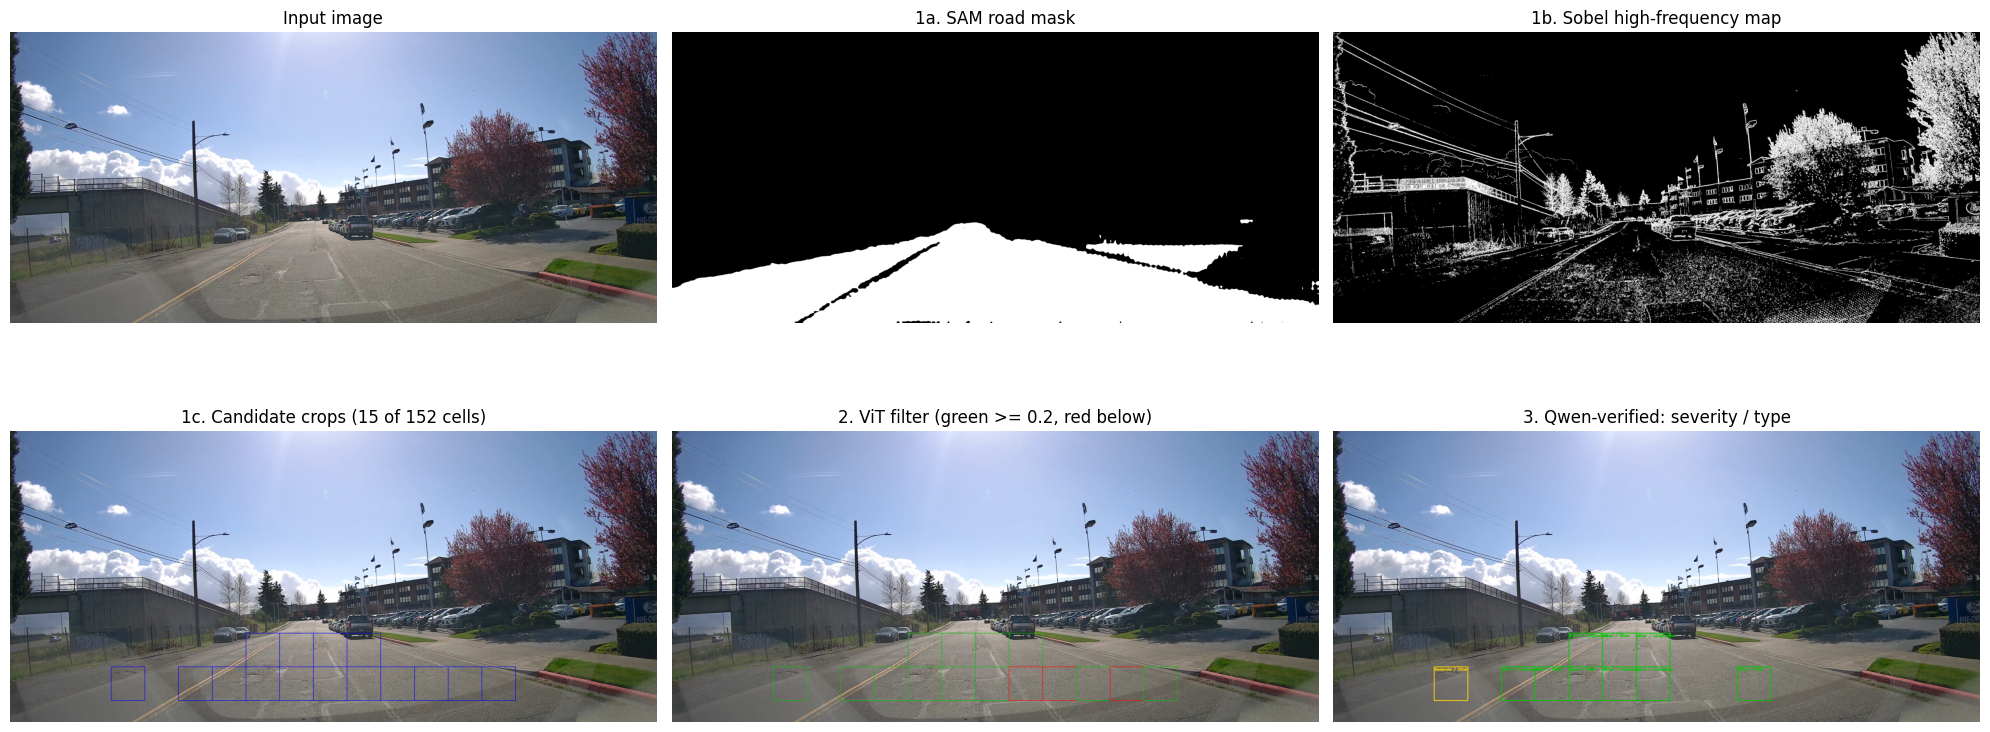

,image_name,crop_x,crop_y,crop_x_end,crop_y_end,vit_probability,qwen_crack_check,severity,crack_type
0,output_0115.png,1400,1200,1600,1400,0.6994,yes,Minor,Longitudinal
1,output_0115.png,1600,1200,1800,1400,0.5361,yes,Minor,Other
2,output_0115.png,1800,1200,2000,1400,0.5867,yes,Minor,Longitudinal
3,output_0115.png,600,1400,800,1600,0.6470,yes,Moderate,Other
4,output_0115.png,1000,1400,1200,1600,0.5080,yes,Minor,Transverse
5,output_0115.png,1200,1400,1400,1600,0.5758,yes,Minor,Other
6,output_0115.png,1400,1400,1600,1600,0.6280,yes,Minor,Other
7,output_0115.png,1600,1400,1800,1600,0.7256,yes,Minor,Transverse
8,output_0115.png,1800,1400,2000,1600,0.6672,yes,Minor,Transverse
9,output_0115.png,2400,1400,2600,1600,0.4968,yes,Minor,Other


In [ ]:
DEMO_INDEX = 4
demo_path = image_paths[DEMO_INDEX]
img = cv2.imread(demo_path)
rgb = lambda a: cv2.cvtColor(a, cv2.COLOR_BGR2RGB)

road_mask = segment_road(img)
hfc = extract_hfc(img)
boxes, total_cells = find_candidate_crops(img, road_mask, hfc)

cand_vis = img.copy()
for b in boxes:
    cv2.rectangle(cand_vis, (b["x"], b["y"]), (b["x_end"], b["y_end"]), (255, 0, 0), 2)

crops = [img[b["y"]:b["y_end"], b["x"]:b["x_end"]] for b in boxes]
probs = vit_crack_probabilities(crops)
vit_vis = img.copy()
for b, p in zip(boxes, probs):
    keep = p >= VIT_THRESHOLD
    cv2.rectangle(vit_vis, (b["x"], b["y"]), (b["x_end"], b["y_end"]), (0, 200, 0) if keep else (0, 0, 255), 2)

fig, ax = plt.subplots(2, 3, figsize=(20, 9))
ax[0, 0].imshow(rgb(img));                        ax[0, 0].set_title("Input image")
ax[0, 1].imshow(road_mask, cmap="gray");          ax[0, 1].set_title("1a. SAM road mask")
ax[0, 2].imshow(hfc, cmap="gray");                ax[0, 2].set_title("1b. Sobel high-frequency map")
ax[1, 0].imshow(rgb(cand_vis));                   ax[1, 0].set_title(f"1c. Candidate crops ({len(boxes)} of {total_cells} cells)")
ax[1, 1].imshow(rgb(vit_vis));                    ax[1, 1].set_title(f"2. ViT filter (green >= {VIT_THRESHOLD}, red below)")
for a in ax.ravel(): a.axis("off")

dets, funnel, annotated = process_image(demo_path, save_outputs=False)
ax[1, 2].imshow(rgb(annotated));                  ax[1, 2].set_title("3. Qwen-verified: severity / type")
ax[1, 2].axis("off")
plt.tight_layout(); plt.show()

pd.DataFrame(dets)[["image_name", "crop_x", "crop_y", "crop_x_end", "crop_y_end",
                    "vit_probability", "qwen_crack_check", "severity", "crack_type"]] if dets else print("No cracks retained.")

Zoom in on the retained crops with their predictions:

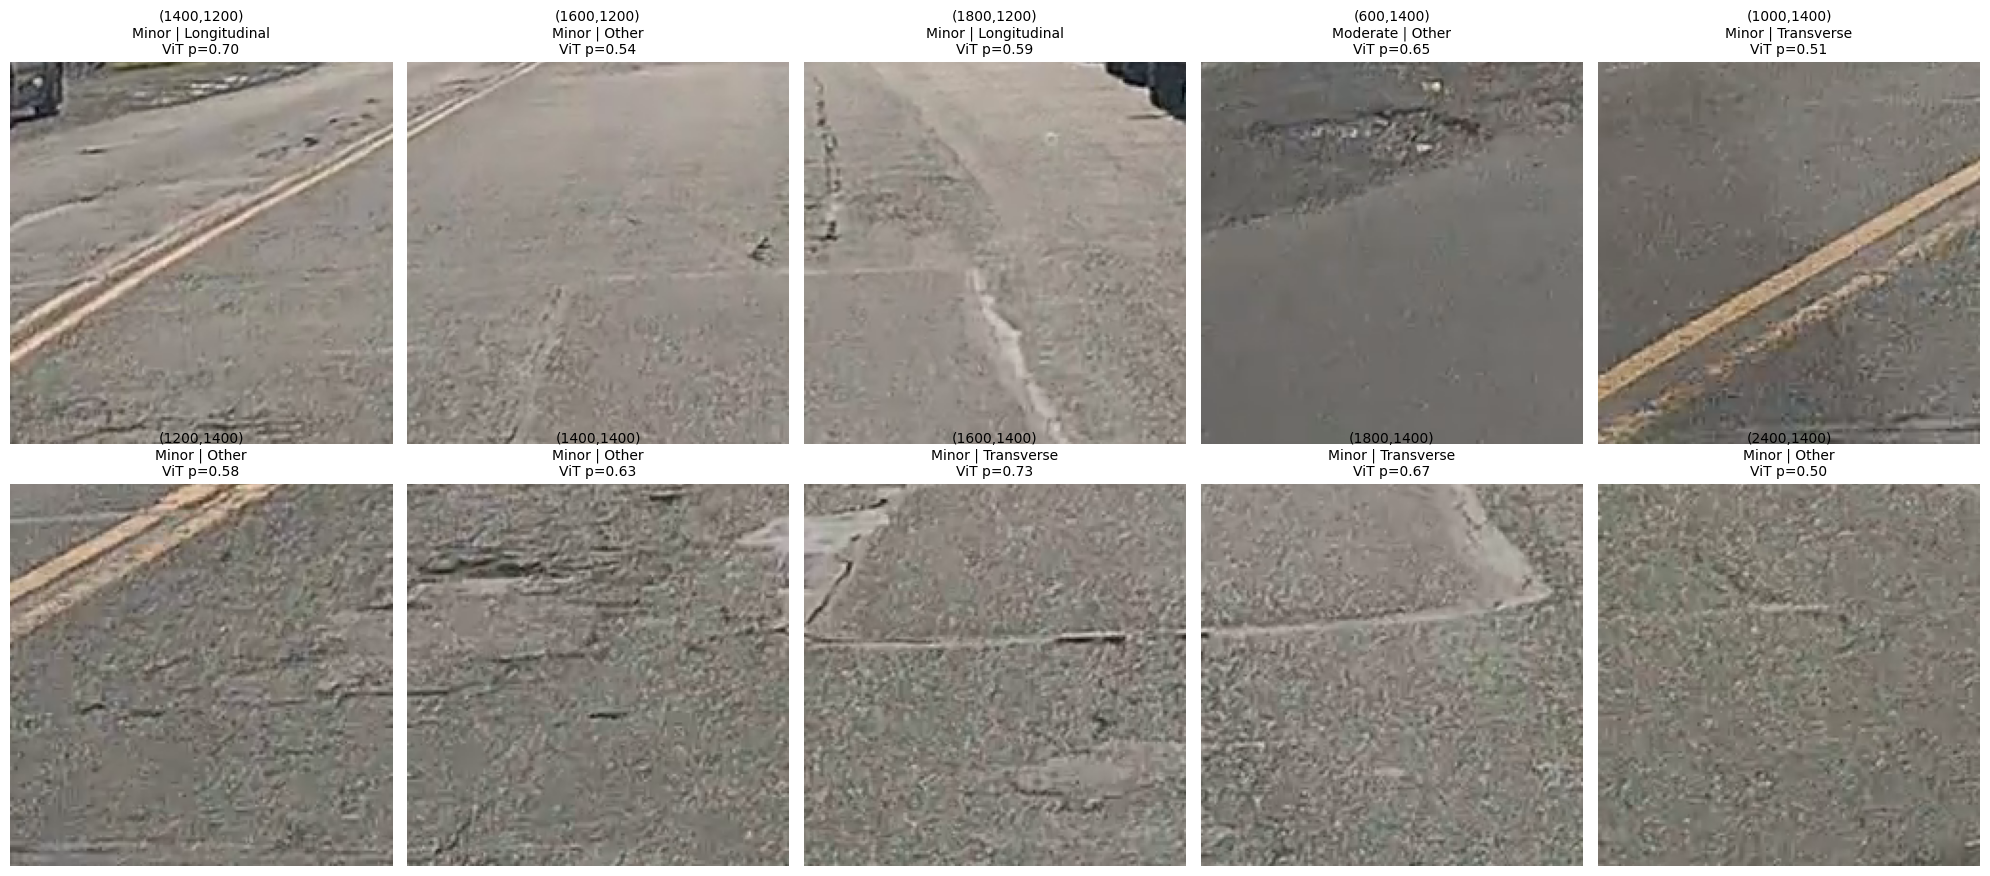

In [ ]:
def show_detection_gallery(detections, image_path, max_n=10):
    if not detections:
        print("Nothing to show."); return
    image = cv2.imread(image_path)
    n = min(len(detections), max_n)
    cols = min(5, n); rows = int(np.ceil(n / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(4 * cols, 4.4 * rows), squeeze=False)
    for a in axes.ravel(): a.axis("off")
    for a, d in zip(axes.ravel(), detections[:n]):
        a.imshow(rgb(image[d["crop_y"]:d["crop_y_end"], d["crop_x"]:d["crop_x_end"]]))
        a.set_title(f"({d['crop_x']},{d['crop_y']})\n{d['severity']} | {d['crack_type']}\nViT p={d['vit_probability']:.2f}", fontsize=10)
    plt.tight_layout(); plt.show()

show_detection_gallery(dets, demo_path)

And the crops that **passed the ViT but were rejected by Qwen** (the false positives the verifier removed):

In [ ]:
print(f"ViT retained {funnel['vit_retained']} crops -> Qwen verified {funnel['qwen_verified']}, rejected {len(last_rejected)}")
if last_rejected:
    n = min(len(last_rejected), 10); cols = min(5, n); rows = int(np.ceil(n / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(4 * cols, 4.2 * rows), squeeze=False)
    for a in axes.ravel(): a.axis("off")
    for a, r in zip(axes.ravel(), last_rejected[:n]):
        a.imshow(rgb(r["crop"]))
        a.set_title(f"({r['box']['x']},{r['box']['y']})  ViT p={r['vit_probability']:.2f}\nQwen: {r['verdict']}", fontsize=10)
    plt.suptitle("Rejected by Qwen verification", fontsize=14)
    plt.tight_layout(); plt.show()

## 6. Run on the full dataset

In [ ]:
all_dets, all_funnel = [], []
for p in tqdm(image_paths, desc="Images"):
    d, f, _ = process_image(p, save_outputs=True)
    all_dets.extend(d); all_funnel.append(f)

COLS = ["image_name", "crop_x", "crop_y", "crop_x_end", "crop_y_end", "center_x", "center_y",
        "vit_probability", "qwen_crack_check", "severity", "crack_type", "crop_file"]
results = pd.DataFrame(all_dets, columns=COLS)
funnel_df = pd.DataFrame(all_funnel)

results.to_csv(f"{OUTPUT_DIR}/crack_results.csv", index=False)
results.to_json(f"{OUTPUT_DIR}/crack_results.json", orient="records", indent=2)
funnel_df.to_csv(f"{OUTPUT_DIR}/funnel_stats.csv", index=False)
print(f"Saved {len(results)} detections from {len(image_paths)} images to {OUTPUT_DIR}")
results.head(20)

Images:   0%|          | 0/5 [00:00<?, ?it/s]

IndexError: index 0 is out of bounds for dimension 0 with size 0

## 7. Results summary

In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(20, 4.5))

# Funnel
totals = funnel_df[["grid_cells", "candidates", "vit_retained", "qwen_verified"]].sum()
ax[0].bar(["All grid\ncells", "SAM+Sobel\ncandidates", "ViT\nretained", "Qwen\nverified"], totals.values, color=["#999", "#4c78a8", "#f58518", "#e45756"])
for i, v in enumerate(totals.values): ax[0].text(i, v, int(v), ha="center", va="bottom")
ax[0].set_title("Pipeline funnel (crops)")

sev_order = ["Extreme", "Severe", "Serious", "Moderate", "Minor", "Negligible", "Unknown"]
results["severity"].value_counts().reindex(sev_order, fill_value=0).plot.bar(ax=ax[1], color="#f58518")
ax[1].set_title("Severity distribution"); ax[1].set_xlabel("")

type_order = ["Longitudinal", "Transverse", "Alligator", "Other", "Unknown"]
results["crack_type"].value_counts().reindex(type_order, fill_value=0).plot.bar(ax=ax[2], color="#54a24b")
ax[2].set_title("Crack type distribution"); ax[2].set_xlabel("")
plt.tight_layout(); plt.show()

print("Per-image summary:")
display(results.groupby("image_name").agg(
    n_cracked_crops=("crop_file", "count"),
    worst_severity=("severity", lambda s: next((x for x in sev_order if x in set(s)), "Unknown")),
).sort_values("n_cracked_crops", ascending=False).head(15))

### Human-readable report

In [ ]:
for _, r in results.iterrows():
    print(f"{r.image_name}  |  crop ({r.crop_x},{r.crop_y})-({r.crop_x_end},{r.crop_y_end})  "
          f"center ({r.center_x},{r.center_y})  |  {r.severity}, {r.crack_type}  (ViT p={r.vit_probability})")

### Browse annotated images

In [ ]:
for name in results["image_name"].unique()[:3]:
    im = cv2.imread(f"{OUTPUT_DIR}/annotated/{name}")
    plt.figure(figsize=(14, 8)); plt.imshow(rgb(im)); plt.axis("off"); plt.title(name); plt.show()

## Output files (in `OUTPUT_DIR`)
| Path | Contents |
|---|---|
| `crack_results.csv` / `.json` | One row per retained crop: image name, crop box + center (pixels, original image coordinates), ViT probability, severity, type |
| `funnel_stats.csv` | Per-image counts at each filter stage |
| `annotated/<image>` | Original image with severity-colored boxes and labels |
| `crops/<image>_x<X>_y<Y>.png` | The individual 200x200 crops that were verified and described |
| `rejected_by_qwen/` | ViT survivors that Qwen judged not to be cracks (useful for auditing the verifier) |

## Notes and limitations
- **SAM prompt is a fixed point** (1/3 across, 79% down). It works for dash-cam views where the road is roughly centered and fails on oddly framed images; check `SAM found no road` messages.
- **The 0.195 threshold trades precision for recall** by design; the Qwen verification stage removes most of the resulting false positives. Review `rejected_by_qwen/` to check that it isn't discarding real cracks (set `QWEN_VERIFY_CRACKS = False` to compare).
- Severity/type labels come from a zero-shot VLM, so treat them as triage aids, not ground truth.